## 1. Import Required Libraries

In [2]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from tqdm import tqdm

print("All image preprocessing libraries imported successfully!")

All image preprocessing libraries imported successfully!


## Inference

All required libraries for image preprocessing
were imported successfully.

OpenCV and Pillow will help process images.
NumPy and Pandas will help manage image data.
Matplotlib will help visualize images.

## 2. Define Dataset Paths

In [3]:
PROJECT_ROOT = Path.cwd().parent

DATASET_PATH = PROJECT_ROOT / "dataset"
RAW_PATH = DATASET_PATH / "raw"
PROCESSED_PATH = DATASET_PATH / "processed"

print("Project Root:", PROJECT_ROOT)
print("Dataset Path:", DATASET_PATH)
print("Raw Dataset Path:", RAW_PATH)
print("Processed Dataset Path:", PROCESSED_PATH)

print("\nRaw folder exists:", RAW_PATH.exists())
print("Processed folder exists:", PROCESSED_PATH.exists())

Project Root: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION
Dataset Path: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\dataset
Raw Dataset Path: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\dataset\raw
Processed Dataset Path: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\dataset\processed

Raw folder exists: True
Processed folder exists: True


## Inference

The dataset paths were defined successfully.

The raw folder contains the original railway images.
The processed folder will store the preprocessed images.

These paths will be used throughout the preprocessing process.

## 3. Identify Image Files

In [5]:
# Identify all image files in the raw dataset

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

image_files = [
    file for file in RAW_PATH.rglob("*")
    if file.suffix.lower() in image_extensions
]

print("Total number of image files:", len(image_files))

Total number of image files: 1017


## Inference
The image files were successfully identified from the raw dataset directory using the specified image file extensions. This step helps determine the total number of images available for further preprocessing and model development.

## 4. Count images by category

In [6]:
# Count images in each category

from collections import Counter

image_counts = Counter(
    file.parent.name for file in image_files
)

print("Images in each category:\n")

for category, count in image_counts.items():
    print(category, ":", count)

Images in each category:

Defective : 515
Non defective : 502


## Inference
The images were grouped and counted based on their respective category folders. This analysis provides an overview of the image distribution across different classes and helps understand the dataset structure.

## 5. Display the first 10 image paths

In [7]:
# Display the first 10 image paths

for file in image_files[:10]:
    print(file)

c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\dataset\raw\RailwayDefectDetectionDatabase V2\RailwayDefectDetectionDatabase\Validation\Defective\2386_3_4_36247.jpg
c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\dataset\raw\RailwayDefectDetectionDatabase V2\RailwayDefectDetectionDatabase\Validation\Defective\2386_3_4_36250.jpg
c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\dataset\raw\RailwayDefectDetectionDatabase V2\RailwayDefectDetectionDatabase\Validation\Defective\2386_3_4_36253.jpg
c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\dataset\raw\RailwayDefectDetectionDatabase V2\RailwayDefectDetectionDatabase\Validation\Defective\2386_3_4_36360.jpg
c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\dataset\raw\RailwayDefectDetectionDatabase V2\RailwayDefectDetectionDatabase\Validation\Defective\2386_3_4_36361.jpg
c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\dataset\raw\RailwayDefectDetectionDatabase V2\RailwayDefectDetectionDatabase\Validation\Defective\2386_3_4_36362.jp

## Inference 
The first ten image file paths were displayed successfully, confirming that the images are being accessed from the correct raw dataset directory. This also verifies the folder organization and image file identification process.

## 6. Check image validity

In [8]:
# Check corrupted and valid images

from PIL import Image

corrupted_images = []
valid_images = []

for file in image_files:
    try:
        with Image.open(file) as img:
            img.verify()

        valid_images.append(file)

    except Exception:
        corrupted_images.append(file)

print("Valid images:", len(valid_images))
print("Corrupted images:", len(corrupted_images))

Valid images: 1017
Corrupted images: 0


## Inference
The identified images were checked for file integrity using the Python Imaging Library (PIL). Images that passed the verification process were classified as valid, while unreadable or damaged images were identified as corrupted. This ensures that only valid images are used in the subsequent preprocessing steps.

## 7. Display corrupted image paths

In [9]:
# Display corrupted image file paths

print("Corrupted image files:\n")

for file in corrupted_images:
    print(file)

Corrupted image files:



## Inference 
The corrupted image file paths were displayed for inspection. If no corrupted images were detected, the dataset is considered suitable for the next preprocessing stage. If corrupted images are present, they will be excluded from further processing to maintain data quality.

## 8. Resize all valid images

In [10]:
# Resize all valid images to a fixed size

target_size = (224, 224)

resized_images = []
resized_paths = []

for file in valid_images:
    with Image.open(file) as img:
        img = img.convert("RGB")
        img = img.resize(target_size)

        resized_images.append(img.copy())
        resized_paths.append(file)

print("Total resized images:", len(resized_images))
print("Target image size:", target_size)

Total resized images: 1017
Target image size: (224, 224)


## Inference
All valid images were resized to a fixed dimension of 224 × 224 pixels and converted into RGB format. Standardizing the image dimensions ensures consistent input shapes, making the images suitable for further preprocessing and CNN model development.

## 9. Normalize image pixel values

In [11]:
# Normalize images to a range of 0 to 1

import numpy as np

normalized_images = []

for img in resized_images:
    image_array = np.array(img, dtype=np.float32)
    normalized_image = image_array / 255.0

    normalized_images.append(normalized_image)

normalized_images = np.array(normalized_images)

print("Normalized images shape:", normalized_images.shape)
print("Minimum pixel value:", normalized_images.min())
print("Maximum pixel value:", normalized_images.max())

Normalized images shape: (1017, 224, 224, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


## Inference
The resized images were converted into NumPy arrays and normalized by dividing their pixel values by 255. As a result, the pixel values were scaled to a range between 0 and 1. This standardization helps the CNN model process image data more efficiently during training.

## 10. Create folders and save resized images

In [12]:
# Save resized images into the processed dataset folder

for img, file in zip(resized_images, resized_paths):
    category = file.parent.name

    category_dir = PROCESSED_PATH / category
    category_dir.mkdir(parents=True, exist_ok=True)

    save_path = category_dir / file.name

    img.save(save_path)

print("Processed images saved successfully!")
print("Processed dataset path:", PROCESSED_PATH)

Processed images saved successfully!
Processed dataset path: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\dataset\processed


## Inference
The resized images were successfully saved into the processed dataset directory, organized according to their respective categories. Maintaining the category-wise folder structure helps preserve the class labels and makes the processed dataset convenient to use for subsequent CNN model training.

## 11. Display processed images

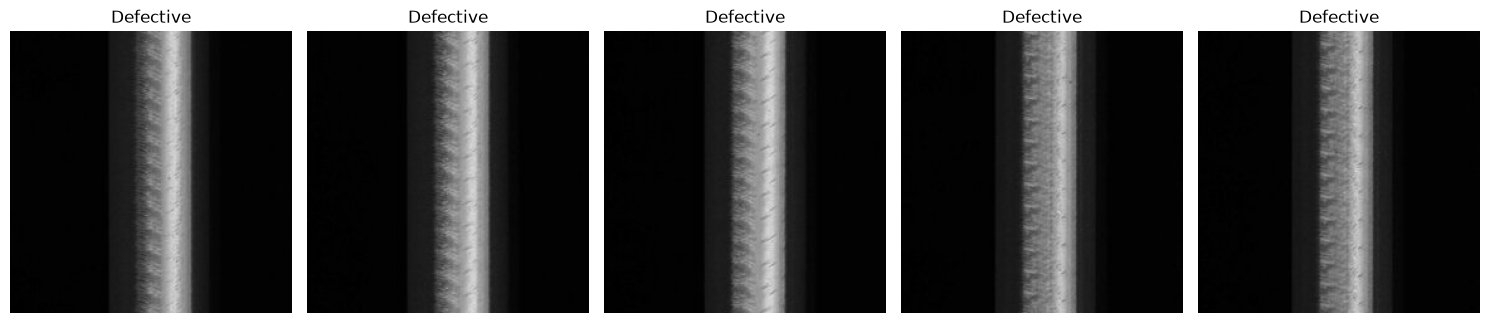

In [13]:
# Visualize the first five processed images

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

for i in range(min(5, len(normalized_images))):
    plt.subplot(1, 5, i + 1)

    plt.imshow(normalized_images[i])
    plt.title(resized_paths[i].parent.name)
    plt.axis("off")

plt.tight_layout()
plt.show()

## Inference
The processed images were visualized to examine their appearance after resizing and normalization. The images retained their visual characteristics and were displayed with consistent dimensions. This confirms that the preprocessing operations were performed appropriately and that the images are ready for the next stage of the project.

## 12. Generate final preprocessing summary

In [14]:
# Final image preprocessing summary

print("=" * 50)
print("IMAGE PREPROCESSING SUMMARY")
print("=" * 50)

print("Total images identified :", len(image_files))
print("Valid images           :", len(valid_images))
print("Corrupted images       :", len(corrupted_images))
print("Images resized         :", len(resized_images))
print("Images normalized      :", len(normalized_images))

print("Target image size      :", target_size)
print("Normalization range    : 0 to 1")
print("Image channels         : RGB (3 channels)")
print("Processed dataset path :", PROCESSED_PATH)

print("=" * 50)
print("IMAGE PREPROCESSING COMPLETED")
print("=" * 50)

IMAGE PREPROCESSING SUMMARY
Total images identified : 1017
Valid images           : 1017
Corrupted images       : 0
Images resized         : 1017
Images normalized      : 1017
Target image size      : (224, 224)
Normalization range    : 0 to 1
Image channels         : RGB (3 channels)
Processed dataset path : c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\dataset\processed
IMAGE PREPROCESSING COMPLETED


## Inference
The image preprocessing workflow was completed successfully. The images were identified, checked for corruption, resized to 224 × 224 pixels, converted into RGB format, normalized to a range of 0–1, and saved in the processed dataset directory. The final summary confirms the preprocessing results and indicates that the processed images are ready for the next stage of CNN model development.